In [1]:
import pandas as pd
import numpy as np
import joblib
import matplotlib.pyplot as plt
from sklearn.inspection import permutation_importance

In [2]:
X_train = pd.read_csv("../data/selected/X_train_selected.csv")
X_val = pd.read_csv("../data/selected/X_val_selected.csv")
X_test = pd.read_csv("../data/selected/X_test_selected.csv")
y_train = pd.read_csv("../data/selected/y_train.csv").squeeze()
y_val = pd.read_csv("../data/selected/y_val.csv").squeeze()
y_test = pd.read_csv("../data/selected/y_test.csv").squeeze()
logistic_model = joblib.load("../models/logistic_regression_optimized.pkl")
decision_tree_model = joblib.load("../models/decision_tree_optimized.pkl")
random_forest_model = joblib.load("../models/random_forest_optimized.pkl")
print("Data and optimized models loaded successfully.")
print("Selected features:", list(X_train.columns))

Data and optimized models loaded successfully.
Selected features: ['n_slash', 'n_hypens', 'n_redirection', 'count', 'n_equal', 'url_length', 'n_and', 'n_dots', 'n_questionmark', 'n_at', 'n_plus', 'n_space', 'n_percent', 'n_dollar', 'n_asterisk']


In [3]:
lr_coefficients = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": logistic_model.coef_[0]
})
lr_coefficients["Absolute_Coefficient"] = (
    lr_coefficients["Coefficient"].abs()
)
lr_coefficients = lr_coefficients.sort_values(
    "Absolute_Coefficient",
    ascending=False
)
print(lr_coefficients.to_string(index=False))

       Feature  Coefficient  Absolute_Coefficient
         count     2.747082              2.747082
          n_at     2.010403              2.010403
n_questionmark     0.637821              0.637821
    n_asterisk     0.623872              0.623872
        n_plus    -0.557268              0.557268
       n_slash     0.485039              0.485039
      n_hypens    -0.351702              0.351702
 n_redirection    -0.232631              0.232631
         n_and    -0.221230              0.221230
      n_dollar     0.142025              0.142025
     n_percent    -0.139640              0.139640
       n_space    -0.128778              0.128778
       n_equal     0.124543              0.124543
        n_dots    -0.082906              0.082906
    url_length     0.021645              0.021645


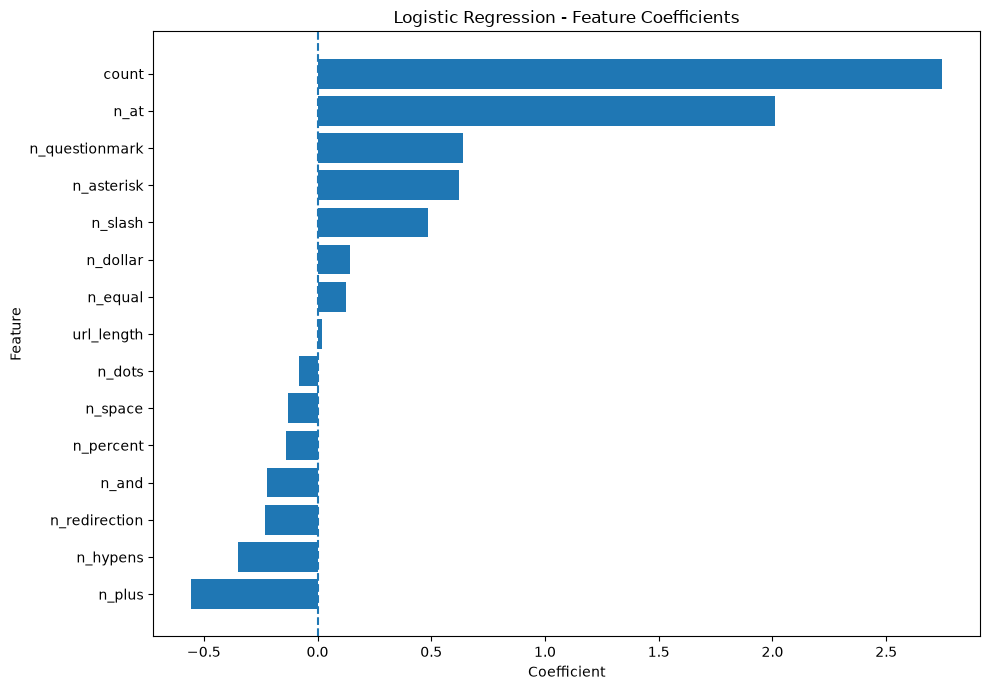

In [4]:
lr_plot = lr_coefficients.sort_values("Coefficient")
plt.figure(figsize=(10, 7))

plt.barh(
    lr_plot["Feature"],
    lr_plot["Coefficient"]
)
plt.axvline(0, linestyle="--")
plt.xlabel("Coefficient")
plt.ylabel("Feature")
plt.title("Logistic Regression - Feature Coefficients")
plt.tight_layout()

plt.savefig(
    "../results/figures/logistic_regression_coefficients.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [5]:
dt_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": decision_tree_model.feature_importances_
})
dt_importance = dt_importance.sort_values(
    "Importance",
    ascending=False
)
print(dt_importance.to_string(index=False))

       Feature  Importance
       n_slash    0.244574
    url_length    0.212370
      n_hypens    0.135000
         count    0.111735
n_questionmark    0.108781
        n_dots    0.095794
 n_redirection    0.039955
     n_percent    0.015550
       n_equal    0.015304
        n_plus    0.008311
          n_at    0.005355
    n_asterisk    0.003950
         n_and    0.002071
       n_space    0.001250
      n_dollar    0.000000


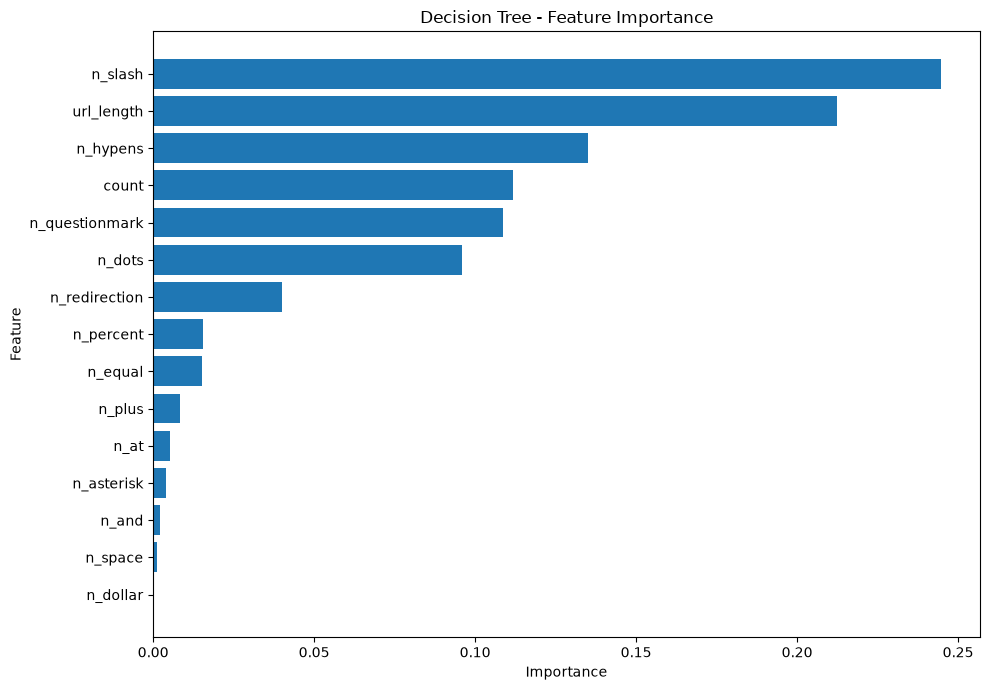

In [6]:
plt.figure(figsize=(10, 7))
plt.barh(
    dt_importance["Feature"],
    dt_importance["Importance"]
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Decision Tree - Feature Importance")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig(
    "../results/figures/decision_tree_feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [7]:
rf_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": random_forest_model.feature_importances_
})
rf_importance = rf_importance.sort_values(
    "Importance",
    ascending=False
)
print(rf_importance.to_string(index=False))

       Feature  Importance
    url_length    0.262728
       n_slash    0.207407
      n_hypens    0.149415
        n_dots    0.096096
         count    0.078671
 n_redirection    0.073715
       n_equal    0.043732
     n_percent    0.024983
         n_and    0.018476
n_questionmark    0.016953
          n_at    0.015336
        n_plus    0.006631
       n_space    0.004820
    n_asterisk    0.000812
      n_dollar    0.000226


In [ ]:
plt.figure(figsize=(10, 7))
plt.barh(
    rf_importance["Feature"],
    rf_importance["Importance"]
)
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest - Feature Importance")
plt.gca().invert_yaxis()

plt.tight_layout()

plt.savefig(
    "../results/figures/random_forest_explainability_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()